## Isolation Forest anomaly-score generation for UAV telemetry

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score, average_precision_score

print("Libraries imported.")

Libraries imported.


## Project paths

In [2]:
BASE_DIR = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project")

OUTPUT_DIR = BASE_DIR / "model_outputs" / "isolation_forest_anomaly_score"
PLOT_DIR = OUTPUT_DIR / "plots"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

print("Base directory:", BASE_DIR)
print("Output directory:", OUTPUT_DIR)
print("Plot directory:", PLOT_DIR)

Base directory: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project
Output directory: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/isolation_forest_anomaly_score
Plot directory: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/isolation_forest_anomaly_score/plots


## find dataset files

In [3]:


def find_file(root_dir, possible_names):
    for name in possible_names:
        matches = list(root_dir.rglob(name))
        if len(matches) > 0:
            print(f"Found {name}: {matches[0]}")
            return matches[0]

    raise FileNotFoundError(f"Could not find any of these files: {possible_names}")


train_path = find_file(BASE_DIR, [
    "train_no_dr_scaled.csv",
    "train_no_dr_imputed_scaled.csv"
])

val_path = find_file(BASE_DIR, [
    "val_no_dr_scaled.csv",
    "val_no_dr_imputed_scaled.csv"
])

test_path = find_file(BASE_DIR, [
    "test_no_dr_scaled.csv",
    "test_no_dr_imputed_scaled.csv"
])


# Load CSV files into dataframes
train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)
test_df = pd.read_csv(test_path)

print("Train path:", train_path)
print("Val path:", val_path)
print("Test path:", test_path)

print("\nTrain shape:", train_df.shape)
print("Val shape:", val_df.shape)
print("Test shape:", test_df.shape)

display(train_df.head())

Found train_no_dr_scaled.csv: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_no_dr/train_no_dr_scaled.csv
Found val_no_dr_scaled.csv: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_no_dr/val_no_dr_scaled.csv
Found test_no_dr_scaled.csv: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_no_dr/test_no_dr_scaled.csv
Train path: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_no_dr/train_no_dr_scaled.csv
Val path: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_no_dr/val_no_dr_scaled.csv
Test path: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_no_dr/test_no_dr_scaled.csv

Train shape: (694549, 14)
Val shape: (138749, 14)
Test shape: (138524, 14)


,log_id,dataset_label,battery_status__cell_count,battery_status__current_a,battery_status__current_filtered_a,battery_status__discharged_mah,battery_status__remaining,battery_status__scale,battery_status__voltage_filtered_v,battery_status__voltage_v,cumulative_energy_wh,power_w,time_s,target_energy_next_60s_wh
0,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,-0.411957,-0.884614,-0.887438,-0.654732,0.530812,-0.492240,-0.418736,-0.414391,-0.343775,-0.617679,-1.091536,0.001262
1,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,-0.411957,-0.884614,-0.887438,-0.654732,0.530812,-0.492240,-0.418736,-0.414391,-0.343775,-0.617679,-1.091260,0.001262
2,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,-0.411957,-0.884614,-0.887438,-0.654732,0.530812,-0.492240,-0.418736,-0.414391,-0.343775,-0.617679,-1.090985,0.001262
3,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,-0.411957,-0.884614,-0.887438,-0.654732,0.530812,-0.492240,-0.418736,-0.414391,-0.343775,-0.617679,-1.090709,0.001262
4,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,-0.411957,-0.838245,-0.891093,-0.654728,0.321380,-0.285151,-0.419166,-0.418824,-0.343772,-0.595105,-1.090433,0.001109


## Select features for Isolation Forest

In [4]:


target_col = "target_energy_next_60s_wh"

exclude_cols = [
    "log_id",
    "dataset_label",
    target_col,
    "anomaly_score",
    "anomaly_flag",
    "anomaly_score_iforest",
    "anomaly_flag_iforest"
]

feature_cols = [
    col for col in train_df.columns
    if col not in exclude_cols
    and pd.api.types.is_numeric_dtype(train_df[col])
]

print("Number of Isolation Forest features:", len(feature_cols))
print(feature_cols)

Number of Isolation Forest features: 11
['battery_status__cell_count', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__voltage_filtered_v', 'battery_status__voltage_v', 'cumulative_energy_wh', 'power_w', 'time_s']


## Missing value check

In [5]:

print("Train missing:", train_df[feature_cols].isna().sum().sum())
print("Val missing:", val_df[feature_cols].isna().sum().sum())
print("Test missing:", test_df[feature_cols].isna().sum().sum())

Train missing: 0
Val missing: 0
Test missing: 0


## Train Isolation Forest using normal training rows only

In [6]:

train_normal_df = train_df[train_df["dataset_label"] == "normal"].copy()

print("Training rows total:", len(train_df))
print("Normal training rows used for Isolation Forest:", len(train_normal_df))
print("Abnormal training rows excluded:", (train_df["dataset_label"] == "abnormal").sum())

assert len(train_normal_df) > 0, "No normal training rows found."

Training rows total: 694549
Normal training rows used for Isolation Forest: 497250
Abnormal training rows excluded: 197299


## Optional sampling for faster Isolation Forest training


In [ ]:


MAX_NORMAL_TRAIN_ROWS = 200_000

if len(train_normal_df) > MAX_NORMAL_TRAIN_ROWS:
    train_normal_sample = train_normal_df.sample(
        n=MAX_NORMAL_TRAIN_ROWS,
        random_state=42
    )
    print(f"Sampled {MAX_NORMAL_TRAIN_ROWS:,} normal rows for training.")
else:
    train_normal_sample = train_normal_df.copy()
    print("Using all normal training rows.")

X_train_normal = train_normal_sample[feature_cols].to_numpy(dtype=np.float32)

print("Isolation Forest training matrix:", X_train_normal.shape)


Sampled 200,000 normal rows for training.
Isolation Forest training matrix: (200000, 11)


## Train Isolation Forest

In [8]:


iforest_model = IsolationForest(
    n_estimators=300,
    max_samples="auto",
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

iforest_model.fit(X_train_normal)

print("Isolation Forest training completed.")

Isolation Forest training completed.


## Score train, validation, and test datasets

In [9]:

def add_iforest_anomaly_score(df, feature_cols, model):
    scored_df = df.copy()

    X = scored_df[feature_cols].to_numpy(dtype=np.float32)

    # score_samples: higher = more normal
    # multiply by -1 so higher = more anomalous
    scored_df["anomaly_score_iforest"] = -model.score_samples(X)

    return scored_df


train_iforest = add_iforest_anomaly_score(train_df, feature_cols, iforest_model)
val_iforest = add_iforest_anomaly_score(val_df, feature_cols, iforest_model)
test_iforest = add_iforest_anomaly_score(test_df, feature_cols, iforest_model)

print("Isolation Forest anomaly scores created.")
print("Train:", train_iforest.shape)
print("Val:", val_iforest.shape)
print("Test:", test_iforest.shape)

Isolation Forest anomaly scores created.
Train: (694549, 15)
Val: (138749, 15)
Test: (138524, 15)


## Create threshold using normal training rows only

In [10]:
train_normal_scores = train_iforest.loc[
    train_iforest["dataset_label"] == "normal",
    "anomaly_score_iforest"
].dropna()

assert len(train_normal_scores) > 0, "No normal training anomaly scores found."

IFOREST_ANOMALY_THRESHOLD = float(np.percentile(train_normal_scores, 95))

print("Isolation Forest anomaly threshold:", round(IFOREST_ANOMALY_THRESHOLD, 6))
print(f"Computed from {len(train_normal_scores):,} normal training rows.")

for split_name, df in [
    ("Train", train_iforest),
    ("Validation", val_iforest),
    ("Test", test_iforest)
]:
    df["anomaly_flag_iforest"] = (
        df["anomaly_score_iforest"] > IFOREST_ANOMALY_THRESHOLD
    ).astype(int)

    print("\n" + "="*60)
    print(split_name)
    print("="*60)

    print("\nMean anomaly_score_iforest by label:")
    print(df.groupby("dataset_label")["anomaly_score_iforest"].mean().round(6))

    print("\nAnomaly flag percentage by label:")
    print((df.groupby("dataset_label")["anomaly_flag_iforest"].mean() * 100).round(2))

Isolation Forest anomaly threshold: 0.567453
Computed from 497,250 normal training rows.

Train

Mean anomaly_score_iforest by label:
dataset_label
abnormal    0.545835
normal      0.456485
Name: anomaly_score_iforest, dtype: float64

Anomaly flag percentage by label:
dataset_label
abnormal    42.96
normal       5.00
Name: anomaly_flag_iforest, dtype: float64

Validation

Mean anomaly_score_iforest by label:
dataset_label
abnormal    0.573179
normal      0.444517
Name: anomaly_score_iforest, dtype: float64

Anomaly flag percentage by label:
dataset_label
abnormal    64.65
normal       0.34
Name: anomaly_flag_iforest, dtype: float64

Test

Mean anomaly_score_iforest by label:
dataset_label
abnormal    0.438452
normal      0.452492
Name: anomaly_score_iforest, dtype: float64

Anomaly flag percentage by label:
dataset_label
abnormal    0.28
normal      6.60
Name: anomaly_flag_iforest, dtype: float64


## Row-level anomaly-score summary

In [11]:

for split_name, df in [
    ("Train", train_iforest),
    ("Validation", val_iforest),
    ("Test", test_iforest)
]:
    print("\n" + "="*70)
    print(split_name)
    print("="*70)

    print("\nRows by label:")
    print(df["dataset_label"].value_counts())

    print("\nAnomaly score summary by label:")
    print(
        df.groupby("dataset_label")["anomaly_score_iforest"]
        .describe()
        .round(6)
    )

    print("\nAnomaly flag count by label:")
    print(pd.crosstab(df["dataset_label"], df["anomaly_flag_iforest"]))


Train

Rows by label:
dataset_label
normal      497250
abnormal    197299
Name: count, dtype: int64

Anomaly score summary by label:
                  count      mean       std       min       25%       50%  \
dataset_label                                                               
abnormal       197299.0  0.545835  0.120274  0.399508  0.427669  0.507526   
normal         497250.0  0.456485  0.056419  0.389254  0.418502  0.443787   

                    75%       max  
dataset_label                      
abnormal       0.648738  0.773289  
normal         0.474726  0.761106  

Anomaly flag count by label:
anomaly_flag_iforest       0      1
dataset_label                      
abnormal              112543  84756
normal                472389  24861

Validation

Rows by label:
dataset_label
normal      92724
abnormal    46025
Name: count, dtype: int64

Anomaly score summary by label:
                 count      mean       std       min       25%       50%  \
dataset_label             

##  Flight-level Isolation Forest anomaly-score summary

In [12]:

def create_flight_summary(df):
    flight_summary = (
        df.groupby(["log_id", "dataset_label"])
        .agg(
            mean_iforest_score=("anomaly_score_iforest", "mean"),
            max_iforest_score=("anomaly_score_iforest", "max"),
            flagged_percentage_iforest=("anomaly_flag_iforest", "mean"),
            rows=("anomaly_score_iforest", "size")
        )
        .reset_index()
    )

    flight_summary["flagged_percentage_iforest"] *= 100

    return flight_summary


for split_name, df in [
    ("Train", train_iforest),
    ("Validation", val_iforest),
    ("Test", test_iforest)
]:
    print("\n" + "="*70)
    print(split_name)
    print("="*70)

    flight_summary = create_flight_summary(df)

    print("\nFlight-level mean Isolation Forest score by label:")
    print(
        flight_summary
        .groupby("dataset_label")["mean_iforest_score"]
        .describe()
        .round(6)
    )

    print("\nFlight-level flagged percentage by label:")
    print(
        flight_summary
        .groupby("dataset_label")["flagged_percentage_iforest"]
        .describe()
        .round(2)
    )

    print("\nTop 10 highest Isolation Forest anomaly-score flights:")
    display(
        flight_summary
        .sort_values("mean_iforest_score", ascending=False)
        .head(10)
    )


Train

Flight-level mean Isolation Forest score by label:
               count      mean       std       min       25%       50%  \
dataset_label                                                            
abnormal        29.0  0.529557  0.107662  0.408793  0.431543  0.487958   
normal          88.0  0.448509  0.045581  0.400989  0.418648  0.433396   

                    75%       max  
dataset_label                      
abnormal       0.624306  0.753812  
normal         0.463535  0.673789  

Flight-level flagged percentage by label:
               count   mean    std  min  25%    50%     75%    max
dataset_label                                                     
abnormal        29.0  38.11  45.53  0.0  0.0  14.54  100.00  100.0
normal          88.0   3.60  15.25  0.0  0.0   0.00    0.37  100.0

Top 10 highest Isolation Forest anomaly-score flights:


,log_id,dataset_label,mean_iforest_score,max_iforest_score,flagged_percentage_iforest,rows
113,f2ffd430-5ef3-4de2-b60e-b47d6cf044b2,abnormal,0.753812,0.770677,100.000000,9693
38,3d552044-12aa-4b10-919d-2bdfa037425a,abnormal,0.734822,0.773289,100.000000,18163
21,1b0a05cf-c1a5-4cc0-90db-39da30779ca8,abnormal,0.700932,0.714664,100.000000,4247
82,aa7ed643-e8a7-478e-917f-34dc50b33916,abnormal,0.683745,0.717216,100.000000,6177
53,670aaff6-ba17-4047-ae2c-53e26d74bf74,normal,0.673789,0.708732,97.482592,3734
58,75678c0f-b911-4875-a2cf-bc317c489c22,abnormal,0.667822,0.725228,100.000000,10207
2,0226edf3-a838-48f9-b932-1882f5353d20,normal,0.663164,0.761106,100.000000,13433
4,06b760bf-d457-46b7-84e1-f08c180aefb3,abnormal,0.638486,0.651423,99.914501,5848
67,80bfac4b-fa67-4fc7-8833-7789229fb78f,abnormal,0.627869,0.677613,100.000000,2850
1,00a25d12-c11a-46d2-a704-e2abe3fd38c6,abnormal,0.624306,0.722707,81.093255,8214



Validation

Flight-level mean Isolation Forest score by label:
               count      mean       std       min       25%       50%  \
dataset_label                                                            
abnormal         6.0  0.537214  0.118247  0.419209  0.430863  0.530456   
normal          19.0  0.442265  0.030376  0.405657  0.421386  0.429072   

                    75%       max  
dataset_label                      
abnormal       0.632516  0.678962  
normal         0.460221  0.527899  

Flight-level flagged percentage by label:
               count   mean    std  min  25%    50%    75%     max
dataset_label                                                     
abnormal         6.0  46.26  51.15  0.0  0.0  39.94  93.24  100.00
normal          19.0   0.21   0.61  0.0  0.0   0.00   0.03    2.51

Top 10 highest Isolation Forest anomaly-score flights:


,log_id,dataset_label,mean_iforest_score,max_iforest_score,flagged_percentage_iforest,rows
14,85906799-2093-4ed3-854a-9bc6f7c24516,abnormal,0.678962,0.720830,97.698113,2650
4,25c37f03-8611-4026-bb3a-ae908b19fb71,abnormal,0.640405,0.711003,100.000000,14615
19,d6daaf48-1a74-40a2-bb08-35f821bd5b52,abnormal,0.608850,0.703207,79.871452,15714
13,83b00da7-f696-4af4-b3b7-f768fead3c7f,normal,0.527899,0.547335,0.000000,5833
3,160089e9-4cd9-4e8f-9bf9-d5395565c17f,normal,0.479309,0.573081,0.192678,3114
15,91c75978-66ee-48d4-9403-437c2320480b,normal,0.470726,0.608170,1.123343,4451
9,543dd620-36c7-49f1-8077-e90b707e612f,normal,0.461152,0.594849,0.148965,6713
22,de64ee71-615d-4dea-902f-116b4d9581e8,normal,0.460687,0.577808,0.065266,7661
2,0b7bf455-91a5-497b-ae0f-c021491c15fc,normal,0.459755,0.546488,0.000000,3066
8,4633646c-e55e-4c54-8c6f-a8df6c1502bf,normal,0.455693,0.579413,2.505695,9658



Test

Flight-level mean Isolation Forest score by label:
               count      mean       std       min       25%       50%  \
dataset_label                                                            
abnormal         7.0  0.438332  0.019108  0.414323  0.425820  0.432600   
normal          19.0  0.442568  0.034492  0.404150  0.427446  0.437035   

                    75%       max  
dataset_label                      
abnormal       0.452003  0.465752  
normal         0.447756  0.563632  

Flight-level flagged percentage by label:
               count  mean    std  min  25%  50%   75%    max
dataset_label                                                
abnormal         7.0  0.29   0.60  0.0  0.0  0.0  0.22   1.60
normal          19.0  3.50  12.58  0.0  0.0  0.0  0.27  54.57

Top 10 highest Isolation Forest anomaly-score flights:


,log_id,dataset_label,mean_iforest_score,max_iforest_score,flagged_percentage_iforest,rows
15,bc1ff53c-5aae-430f-9787-f5182e51af31,normal,0.563632,0.715572,54.572422,9776
20,d81d545a-d757-4357-821f-957c661ceba1,normal,0.475755,0.644616,10.053046,11688
24,ecff5324-be68-4990-902d-70b50b4def92,abnormal,0.465752,0.593328,0.441618,5661
14,9b9969e9-f490-4761-88b9-dea3c1de6e28,normal,0.463990,0.656783,0.810024,7901
8,7221cc23-2f78-4b80-bc07-831a7f8b7d38,abnormal,0.459809,0.561001,0.000000,4085
7,5e9e00ef-d5aa-4d99-af60-b8b45ab2f1f8,normal,0.452683,0.496240,0.000000,3145
19,d321f2ff-c7e1-4534-997b-d0ca36faf495,normal,0.449071,0.592170,0.510595,3917
4,3179d5d2-e991-4a7a-b4cd-5c1bd02eb806,normal,0.446441,0.515354,0.000000,7664
17,c839b5f0-b619-4e68-92e6-5b9a82465c72,abnormal,0.444197,0.545712,0.000000,7119
13,9499b371-621a-4ddf-a928-a524ce220057,normal,0.443114,0.493805,0.000000,2925


##  Flight-level anomaly detection performance

In [13]:

# Validation and test only

print("\n" + "="*70)
print("FLIGHT-LEVEL ISOLATION FOREST ANOMALY DETECTION PERFORMANCE")
print("="*70)

iforest_detection_results = []

for split_name, df in [
    ("Validation", val_iforest),
    ("Test", test_iforest)
]:
    flight_level = (
        df.groupby(["log_id", "dataset_label"])["anomaly_score_iforest"]
        .mean()
        .reset_index()
        .rename(columns={"anomaly_score_iforest": "mean_iforest_score"})
    )

    flight_level["binary_label"] = (
        flight_level["dataset_label"] == "abnormal"
    ).astype(int)

    n_normal = int((flight_level["binary_label"] == 0).sum())
    n_abnormal = int((flight_level["binary_label"] == 1).sum())

    print("\n" + "-"*70)
    print(split_name)
    print("-"*70)
    print("Normal flights:", n_normal)
    print("Abnormal flights:", n_abnormal)

    if flight_level["binary_label"].nunique() < 2:
        print("Only one class present. AUROC/AUPRC skipped.")

        iforest_detection_results.append({
            "split": split_name,
            "normal_flights": n_normal,
            "abnormal_flights": n_abnormal,
            "flight_level_auroc": np.nan,
            "flight_level_auprc": np.nan,
            "baseline_auprc": np.nan
        })

        continue

    auroc = roc_auc_score(
        flight_level["binary_label"],
        flight_level["mean_iforest_score"]
    )

    auprc = average_precision_score(
        flight_level["binary_label"],
        flight_level["mean_iforest_score"]
    )

    baseline_auprc = flight_level["binary_label"].mean()

    print(f"Flight-level AUROC : {auroc:.4f}")
    print(f"Flight-level AUPRC : {auprc:.4f}")
    print(f"Baseline AUPRC     : {baseline_auprc:.4f}")

    iforest_detection_results.append({
        "split": split_name,
        "normal_flights": n_normal,
        "abnormal_flights": n_abnormal,
        "flight_level_auroc": auroc,
        "flight_level_auprc": auprc,
        "baseline_auprc": baseline_auprc
    })

iforest_detection_results_df = pd.DataFrame(iforest_detection_results)

display(iforest_detection_results_df.round(4))

iforest_detection_results_path = OUTPUT_DIR / "iforest_flight_level_anomaly_detection_results.csv"
iforest_detection_results_df.to_csv(iforest_detection_results_path, index=False)

print("\nSaved results to:")
print(iforest_detection_results_path)


FLIGHT-LEVEL ISOLATION FOREST ANOMALY DETECTION PERFORMANCE

----------------------------------------------------------------------
Validation
----------------------------------------------------------------------
Normal flights: 19
Abnormal flights: 6
Flight-level AUROC : 0.6930
Flight-level AUPRC : 0.6522
Baseline AUPRC     : 0.2400

----------------------------------------------------------------------
Test
----------------------------------------------------------------------
Normal flights: 19
Abnormal flights: 7
Flight-level AUROC : 0.4962
Flight-level AUPRC : 0.3119
Baseline AUPRC     : 0.2692


,split,normal_flights,abnormal_flights,flight_level_auroc,flight_level_auprc,baseline_auprc
0,Validation,19,6,0.6930,0.6522,0.2400
1,Test,19,7,0.4962,0.3119,0.2692



Saved results to:
/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/isolation_forest_anomaly_score/iforest_flight_level_anomaly_detection_results.csv


## Plot Isolation Forest anomaly-score distributions

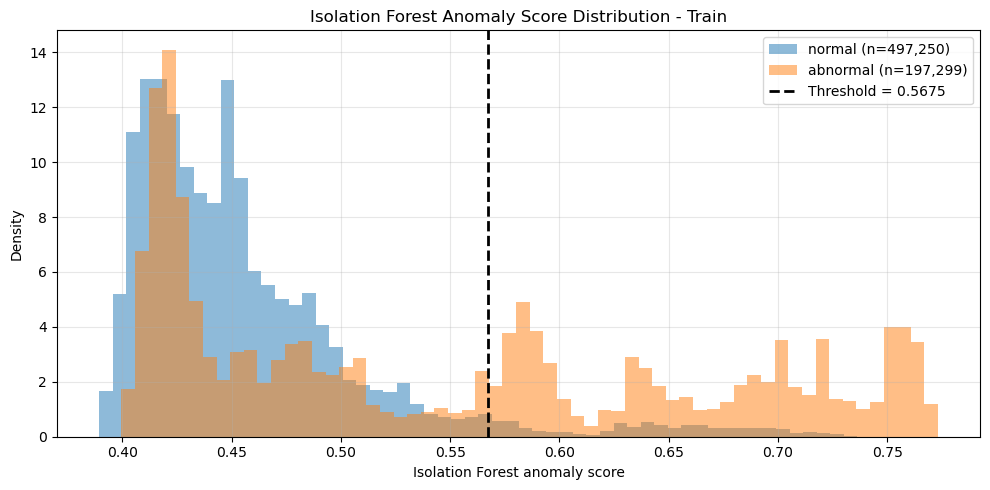

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/isolation_forest_anomaly_score/plots/iforest_anomaly_score_distribution_train.png


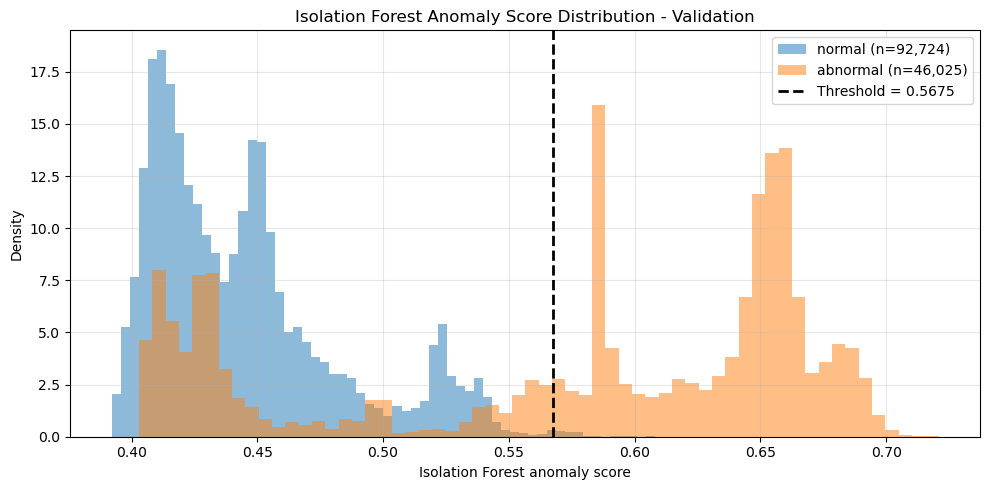

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/isolation_forest_anomaly_score/plots/iforest_anomaly_score_distribution_validation.png


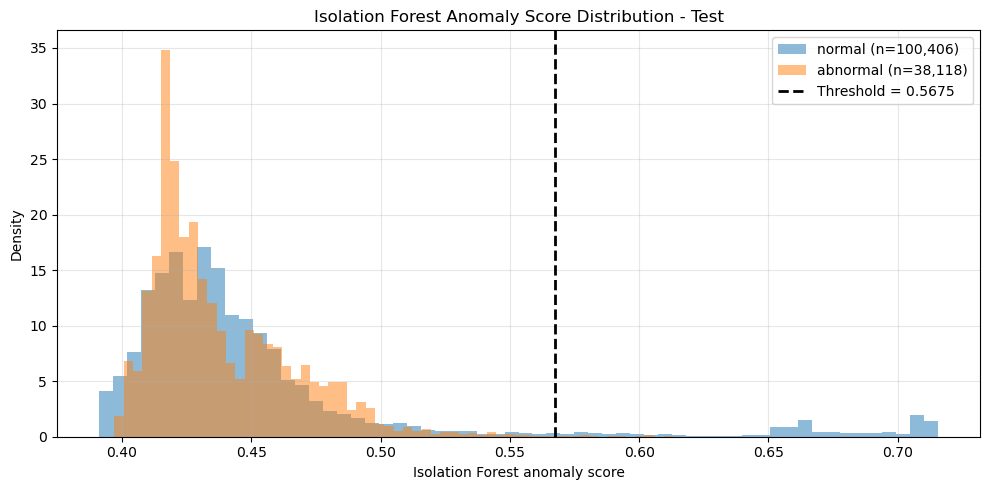

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/isolation_forest_anomaly_score/plots/iforest_anomaly_score_distribution_test.png


In [14]:
for split_name, df in [
    ("Train", train_iforest),
    ("Validation", val_iforest),
    ("Test", test_iforest)
]:
    plt.figure(figsize=(10, 5))

    for label in ["normal", "abnormal"]:
        subset = df[df["dataset_label"] == label]

        if len(subset) > 0:
            plt.hist(
                subset["anomaly_score_iforest"],
                bins=60,
                alpha=0.5,
                density=True,
                label=f"{label} (n={len(subset):,})"
            )

    plt.axvline(
        IFOREST_ANOMALY_THRESHOLD,
        linestyle="--",
        linewidth=2,
        color="black",
        label=f"Threshold = {IFOREST_ANOMALY_THRESHOLD:.4f}"
    )

    plt.xlabel("Isolation Forest anomaly score")
    plt.ylabel("Density")
    plt.title(f"Isolation Forest Anomaly Score Distribution - {split_name}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    save_path = PLOT_DIR / f"iforest_anomaly_score_distribution_{split_name.lower()}.png"
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Saved:", save_path)

## Save datasets with Isolation Forest anomaly score

In [15]:


train_save_path = OUTPUT_DIR / "train_no_dr_with_iforest_anomaly_score.csv"
val_save_path = OUTPUT_DIR / "val_no_dr_with_iforest_anomaly_score.csv"
test_save_path = OUTPUT_DIR / "test_no_dr_with_iforest_anomaly_score.csv"

train_iforest.to_csv(train_save_path, index=False)
val_iforest.to_csv(val_save_path, index=False)
test_iforest.to_csv(test_save_path, index=False)

print("Saved:")
print(train_save_path)
print(val_save_path)
print(test_save_path)

Saved:
/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/isolation_forest_anomaly_score/train_no_dr_with_iforest_anomaly_score.csv
/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/isolation_forest_anomaly_score/val_no_dr_with_iforest_anomaly_score.csv
/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/isolation_forest_anomaly_score/test_no_dr_with_iforest_anomaly_score.csv


## Final output summary

In [16]:


print("\n" + "="*60)
print("FINAL ISOLATION FOREST OUTPUT SUMMARY")
print("="*60)

for split_name, df in [
    ("Train", train_iforest),
    ("Validation", val_iforest),
    ("Test", test_iforest)
]:
    print("\n" + split_name)
    print("-" * len(split_name))

    print("Shape:", df.shape)
    print("Missing anomaly_score_iforest:", df["anomaly_score_iforest"].isna().sum())
    print("Missing anomaly_flag_iforest:", df["anomaly_flag_iforest"].isna().sum())

    print("\nColumns added:")
    print(["anomaly_score_iforest", "anomaly_flag_iforest"])

    print("\nMean Isolation Forest anomaly score by label:")
    print(df.groupby("dataset_label")["anomaly_score_iforest"].mean().round(6))

    print("\nFlag percentage by label:")
    print((df.groupby("dataset_label")["anomaly_flag_iforest"].mean() * 100).round(2))

print("\nNotebook 05b complete.")
print("Isolation Forest anomaly-score files are ready for notebook 06.")


FINAL ISOLATION FOREST OUTPUT SUMMARY

Train
-----
Shape: (694549, 16)
Missing anomaly_score_iforest: 0
Missing anomaly_flag_iforest: 0

Columns added:
['anomaly_score_iforest', 'anomaly_flag_iforest']

Mean Isolation Forest anomaly score by label:
dataset_label
abnormal    0.545835
normal      0.456485
Name: anomaly_score_iforest, dtype: float64

Flag percentage by label:
dataset_label
abnormal    42.96
normal       5.00
Name: anomaly_flag_iforest, dtype: float64

Validation
----------
Shape: (138749, 16)
Missing anomaly_score_iforest: 0
Missing anomaly_flag_iforest: 0

Columns added:
['anomaly_score_iforest', 'anomaly_flag_iforest']

Mean Isolation Forest anomaly score by label:
dataset_label
abnormal    0.573179
normal      0.444517
Name: anomaly_score_iforest, dtype: float64

Flag percentage by label:
dataset_label
abnormal    64.65
normal       0.34
Name: anomaly_flag_iforest, dtype: float64

Test
----
Shape: (138524, 16)
Missing anomaly_score_iforest: 0
Missing anomaly_flag_ifor

## 7 ABNORMAL TEST FLIGHTS

In [17]:

test_flight_summary = (
    test_iforest
    .groupby(["log_id", "dataset_label"])
    .agg(
        mean_iforest_score=("anomaly_score_iforest", "mean"),
        std_iforest_score=("anomaly_score_iforest", "std"),
        mean_power_w=("power_w", "mean"),
        mean_current=("battery_status__current_a", "mean"),
        mean_voltage=("battery_status__voltage_filtered_v", "mean"),
        mean_remaining=("battery_status__remaining", "mean"),
        n_rows=("anomaly_score_iforest", "count")
    )
    .reset_index()
)

abnormal_test = test_flight_summary[
    test_flight_summary["dataset_label"] == "abnormal"
].sort_values("mean_iforest_score", ascending=False)

normal_test = test_flight_summary[
    test_flight_summary["dataset_label"] == "normal"
]

print("="*70)
print("THE 7 ABNORMAL TEST FLIGHTS")
print("="*70)
print(abnormal_test.to_string(index=False))

print("\n" + "="*70)
print("NORMAL TEST FLIGHTS — REFERENCE STATISTICS")
print("="*70)
print(normal_test.describe().round(4).to_string())

print("\n" + "="*70)
print("COMPARISON: abnormal vs normal test means")
print("="*70)
print(f"Normal   mean power_w   : {normal_test['mean_power_w'].mean():.4f}")
print(f"Abnormal mean power_w   : {abnormal_test['mean_power_w'].mean():.4f}")
print(f"Normal   mean voltage   : {normal_test['mean_voltage'].mean():.4f}")
print(f"Abnormal mean voltage   : {abnormal_test['mean_voltage'].mean():.4f}")
print(f"Normal   mean current   : {normal_test['mean_current'].mean():.4f}")
print(f"Abnormal mean current   : {abnormal_test['mean_current'].mean():.4f}")
print(f"Normal   mean remaining : {normal_test['mean_remaining'].mean():.4f}")
print(f"Abnormal mean remaining : {abnormal_test['mean_remaining'].mean():.4f}")

THE 7 ABNORMAL TEST FLIGHTS
                              log_id dataset_label  mean_iforest_score  std_iforest_score  mean_power_w  mean_current  mean_voltage  mean_remaining  n_rows
ecff5324-be68-4990-902d-70b50b4def92      abnormal            0.465752           0.020478      0.080069      0.196866      0.113605       -0.209419    5661
7221cc23-2f78-4b80-bc07-831a7f8b7d38      abnormal            0.459809           0.021354     -0.205546      0.049982     -0.565801       -1.356554    4085
c839b5f0-b619-4e68-92e6-5b9a82465c72      abnormal            0.444197           0.030652     -0.307548     -0.212383     -0.460037       -0.791794    7119
fd0f9483-c16c-4b19-bc3e-f61311a29003      abnormal            0.432600           0.031250      0.143877      0.711930     -0.450222       -0.249731    5001
0f21527d-77c0-4b01-8130-4ac7b0f9a503      abnormal            0.429045           0.023690      0.119848      0.670060     -0.461570       -0.470054    5378
84a61f31-acce-4b7d-905f-9ed6688ebc9d

In [18]:
abnormal_test_ids = test_iforest[
    test_iforest["dataset_label"] == "abnormal"
]["log_id"].unique()

print("The 7 abnormal test flight IDs:")
for fid in abnormal_test_ids:
    print(f"  {fid}")

The 7 abnormal test flight IDs:
  0f21527d-77c0-4b01-8130-4ac7b0f9a503
  7221cc23-2f78-4b80-bc07-831a7f8b7d38
  7f845837-4460-467a-b8a9-f97d8e6eaab4
  84a61f31-acce-4b7d-905f-9ed6688ebc9d
  c839b5f0-b619-4e68-92e6-5b9a82465c72
  ecff5324-be68-4990-902d-70b50b4def92
  fd0f9483-c16c-4b19-bc3e-f61311a29003
